# Prototype notebook

This is the original single-notebook version of the pipeline, kept because the
recorded FIFA run in the README came from it. The maintained code is the
`news_verifier` package in the repo root.

Differences from the package: this version has no cap on rectification rounds,
and it needs a few extra packages that are not in `requirements.txt`
(`langchain`, `langchain-community`, `langchain-fireworks`).


In [1]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Literal, Annotated
from langchain_core.messages import HumanMessage, AIMessage, BaseMessage
from dotenv import load_dotenv
from langchain_fireworks import ChatFireworks
from langchain_community.tools import DuckDuckGoSearchRun
from langchain_core.tools import tool
from langchain_groq import ChatGroq
from langchain.agents import create_agent
import operator
import json
import re

In [2]:
load_dotenv()
model1 = ChatGroq(model = "openai/gpt-oss-120b", temperature=0)
model2 = ChatGroq(model = "llama-3.3-70b-versatile", temperature=0)
search = DuckDuckGoSearchRun()

In [3]:
class NewsState(TypedDict):
    topic: str
    messages: Annotated[list[BaseMessage],operator.add]
    next_agent: str
    generated_news: str
    evaluation: Literal["genuine","needs_correction", "pending"]
    confidence_history: Annotated[list[float], operator.add]
    feedback: str
    confidence: float
    rectified_news: str
    iteration: int
    final_article: str
    stopping_decision: Literal["stop","continue", "pending"]
    stop_reason: str

In [4]:
@tool
def search_web(query: str) -> str:
    """Searches the web using DuckDuckGo."""
    return search.run(query)


@tool
def fact_check(claim: str) -> str:
    """Fact checks a specific claim."""
    return search.run(f"fact check {claim}")


@tool
def fetch_sources(topic: str) -> str:
    """Fetch real trusted news sources."""
    query = (
        f"latest news about {topic} "
        f"site:reuters.com OR site:bbc.com OR site:apnews.com"
    )

    return search.run(query)


@tool
def rewrite_article(original: str, feedback: str) -> str:
    """
    Rewrite article correcting factual issues.
    """

    response = model2.invoke(
        f"""
Rewrite this article correcting all inaccuracies.

FEEDBACK:
{feedback}

ORIGINAL ARTICLE:
{original}

Return ONLY the corrected article.
"""
    )

    return response.content

In [5]:
generator_agent = create_agent(
    model=model2,

    tools=[],

    system_prompt="""
You are a synthetic news generation agent.

Your goal:
- Generate a highly realistic-looking news article.
- The article MAY contain fabricated or inaccurate details.
- Make the article believable using:
  - names
  - dates
  - organizations
  - statistics
  - technical details

DO NOT mention that the article is fictional.

Write 4-6 sentences.

End response with:

GENERATED_ARTICLE: <article>
"""
)

In [6]:
def supervisor_node(state: NewsState) -> dict:

    generated = state.get("generated_news", "")
    evaluation = state.get("evaluation", "pending")
    stopping_decision = state.get("stopping_decision", "pending")

    if not generated:
        next_agent = "generator"
    elif evaluation == "pending":
        next_agent = "evaluator"
    elif evaluation == "needs_correction" and stopping_decision == "pending":
        next_agent = "stopping_agent"
    elif stopping_decision == "continue":
        next_agent = "rectifier"
    elif stopping_decision == "stop" or evaluation == "genuine":
        next_agent = "FINISH"
    else:
        next_agent = "FINISH"

    print(f"\nSupervisor → {next_agent}")

    return {
        "next_agent": next_agent,
        "messages": [
            AIMessage(content=f"Supervisor routed to: {next_agent}")
        ]
    }

In [7]:
def generator_node(state: NewsState) -> dict:

    print("\nGenerator running...")

    result = generator_agent.invoke({
        "messages": [
            HumanMessage(
                content=(f"Generate a news article about:\n"
                    f"{state['topic']}"
                )
            )
        ]
    })

    raw = result["messages"][-1].content

    if "GENERATED_ARTICLE:" in raw:

        article = raw.split("GENERATED_ARTICLE:")[-1].strip()

    else:
        article = raw

    print("\nGenerated Article:\n")

    print(article)

    return {

        "generated_news": article,

        "evaluation": "pending",

        "messages": [
            AIMessage(
                content=(
                    f"Generated article:\n"
                    f"{article}"
                )
            )
        ]
    }

In [8]:
def evaluator_node(state: NewsState) -> dict:

    print("\nEvaluator running...")

    article = (
        state.get("rectified_news")
        or state.get("generated_news", "")
    )

    search_results = search.run(article[:300])

    prompt = f"""
You are a professional AI fact-checking system.

ARTICLE:
{article}

WEB EVIDENCE:
{search_results}

Tasks:
1. Identify fabricated claims
2. Identify fake names/events/statistics
3. Identify unsupported statements
4. Determine if article is factual overall
5. Give a factual accuracy score between 0.0 to 1.0(factual accuracy score is the confidence score)
   - 0.0 = completely fabricated, no factual basis
   - 0.5 = mix of fact and fiction
   - 1.0 = fully factually accurate and verifiable
   
   This score represents the article's accuracy, NOT your confidence in the evaluation.
Examples:

ARTICLE: "The Eiffel Tower was completed in 1889 and stands 330 metres tall in Paris."
WEB EVIDENCE: [confirms construction date and height]
EVALUATION: genuine
CONFIDENCE: 0.95(factual accuracy score)

ARTICLE: "Spiderman was spotted in Manhattan stopping a bank robbery on Tuesday."
WEB EVIDENCE: [no corroborating sources]
EVALUATION: needs_correction
CONFIDENCE: 0.05(factual accuracy score)

Return STRICTLY in this format:

EVALUATION: genuine
or
EVALUATION: needs_correction

FEEDBACK:
<detailed reasoning>

CONFIDENCE:
<factual accuracy score>
"""

    response = model1.invoke(prompt)
    raw = response.content

    print("\nEvaluator Output:\n")
    print(raw)

    evaluation = "needs_correction"
    feedback = raw
    confidence = 0.0

    match = re.search(r"EVALUATION:\s*(genuine|needs_correction)", raw, re.IGNORECASE)
    if match:
        evaluation = match.group(1).lower()

    if "FEEDBACK:" in raw:
        feedback = raw.split("FEEDBACK:")[-1].strip()
        if "CONFIDENCE:" in feedback:
            feedback = feedback.split("CONFIDENCE:")[0].strip()

    if "CONFIDENCE:" in raw:
        try:
            conf_str = raw.split("CONFIDENCE:")[-1].strip().split()[0]
            confidence = float(conf_str)
        except ValueError:
            confidence = 0.0

    print(f"\nVerdict: {evaluation}")
    print(f"Confidence: {confidence}")

    return {
        "evaluation": evaluation,
        "feedback": feedback,
        "confidence": confidence,
        "confidence_history": [confidence]
    }

In [9]:
def rectifier_node(state: NewsState) -> dict:

    print("\nRectifier running...")

    article = (
        state.get("rectified_news")
        or state["generated_news"]
    )
    article = article[:1000]
    feedback = state["feedback"][:800]

    sources = fetch_sources.invoke({"topic": state["topic"]})

    prompt = f"""
Fix the following article using the real sources provided.
Correct all factual inaccuracies identified in the feedback.

TOPIC:
{state['topic']}

REAL SOURCES:
{sources}

ARTICLE:
{article}

ISSUES:
{feedback}

End with:
RECTIFIED_ARTICLE: <corrected article>
"""

    result = model2.invoke(prompt)
    raw = result.content

    if "RECTIFIED_ARTICLE:" in raw:
        rectified = raw.split("RECTIFIED_ARTICLE:")[-1].strip()
    else:
        rectified = raw

    print("\nRectified Article:\n")
    print(rectified)

    return {
        "rectified_news": rectified,
        "evaluation": "pending",
        "stopping_decision": "pending",
        "iteration": state.get("iteration", 0) + 1,
        "messages": [
            AIMessage(content=f"Rectified article:\n{rectified}")
        ]
    }

In [10]:
def stopping_node(state: NewsState) -> dict:

    print("\n Stopping agent running...")

    article = (
        state.get("rectified_news")
        or state["generated_news"]
    )
    article = article[:1000]
    feedback = state["feedback"][:800]

    prompt=f"""
Check if we can stop rectification and article is factaully correct or we need to continue.

ARTICLE:
{article}

ISSUES:
{feedback}

TOPIC:
{state['topic']}

Confidence:
{state['confidence']}

Consider stopping if:
- Current Confidence is high(near 1.0) 
- No major factual issues remain

Return STRICTLY in this format:

DECISION: continue
or
DECISION: stop

STOPPING REASON:
<short reasoning>
"""
    

    result = model1.invoke(prompt)
    raw = result.content

    decision = "continue" 
    stop_reason = "No reason provided"

    if "DECISION:" in raw:
        try:
            raw_decision = re.sub(r'[^a-z]', '', raw.split("DECISION:")[-1].strip().split()[0].lower())
            if raw_decision in ["stop", "continue"]:
                decision = raw_decision
        except:
            decision = "continue"
    
    if "STOPPING REASON:" in raw:
        stop_reason = raw.split("STOPPING REASON:")[-1].strip()

    print(f"\nDecision: {decision}")
    print(f"Reason: {stop_reason}")


   

    return {

        "stopping_decision" : decision,
        "stop_reason": stop_reason,
        "messages": [
            AIMessage(
                content=(
                    f"Stopping Decision: {decision}"
                    f"Stopping Reason: {stop_reason}"
                )
            )
        ]
    }


In [11]:
def finisher_node(state: NewsState) -> dict:

    final_article = (
        state.get("rectified_news")
        or state.get("generated_news", "")
    )

    print("\n PIPELINE COMPLETE")

    return {
        "final_article": final_article
    }


def route_from_supervisor(
    state: NewsState
) -> str:

    next_agent = state.get( "next_agent","FINISH")

    if next_agent == "FINISH":
        return "finish"

    return next_agent

In [12]:
graph = StateGraph(NewsState)

graph.add_node("supervisor", supervisor_node)
graph.add_node("generator", generator_node)
graph.add_node("evaluator", evaluator_node)
graph.add_node("rectifier", rectifier_node)
graph.add_node("stopping_agent", stopping_node)
graph.add_node("finish", finisher_node)


graph.add_edge(START, "supervisor")
graph.add_conditional_edges(
    "supervisor",
    route_from_supervisor,
    {
        "generator": "generator",
        "evaluator": "evaluator",
        "rectifier": "rectifier",
        "stopping_agent": "stopping_agent",
        "finish": "finish"
    }
)
graph.add_edge("generator", "supervisor")
graph.add_edge("evaluator", "supervisor")
graph.add_edge("rectifier", "supervisor")
graph.add_edge("stopping_agent", "supervisor"),
graph.add_edge("finish", END)

app = graph.compile()

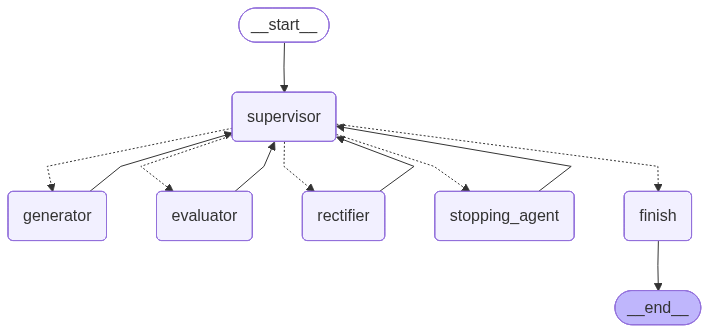

In [13]:
app

In [19]:
result = app.invoke({

    "topic": "FIFA",

    "messages": [],

    "iteration": 0,

    "evaluation": "pending",

    "stopping_decision": "pending",

    "confidence": 0.0,
    
    "confidence_history": [],
    
    "stop_reason": ""
})



print("\nFINAL ARTICLE:\n")

print(result["final_article"])


print(
    f"\nTotal Rectification Loops: "
    f"{result.get('iteration')}"
)



Supervisor → generator

Generator running...

Generated Article:

FIFA Partners with UN to Promote Sustainability in Football

Supervisor → evaluator

Evaluator running...

Evaluator Output:

EVALUATION: needs_correction

FEEDBACK:
The headline “FIFA Partners with UN to Promote Sustainability in Football” suggests a formal, possibly high‑profile partnership between FIFA and the United Nations. The limited web excerpt provided does contain a few relevant points:

* It notes that FIFA is the first international sports organisation to join **Climate Neutral Now**, a United Nations‑run initiative encouraging organisations to offset their carbon emissions.  
* It mentions FIFA’s involvement in sustainability‑related programmes such as the **Qatar 2022 Legacy Fund** and the broader “Football Unites the World” umbrella, which are real FIFA‑led projects.

These fragments confirm that FIFA has engaged with UN‑related climate and sustainability initiatives, but they do **not** demonstrate a new

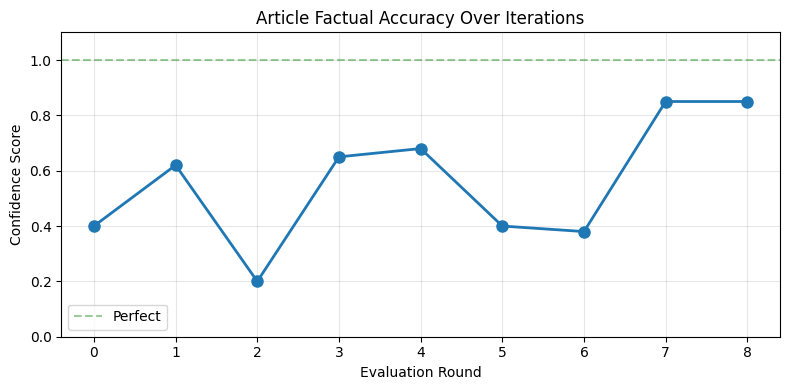

In [20]:
import matplotlib.pyplot as plt

history = result.get("confidence_history", [])

plt.figure(figsize=(8, 4))
plt.plot(history, marker='o', linewidth=2, markersize=8)
plt.axhline(y=1.0, color='g', linestyle='--', alpha=0.4, label='Perfect')
plt.xlabel("Evaluation Round")
plt.ylabel("Confidence Score")
plt.title("Article Factual Accuracy Over Iterations")
plt.xticks(range(len(history)))
plt.ylim(0, 1.1)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()